# C0 · synthetic mechanism study: does transfer fall with training-set size and capacity? (plan §9)

**Question.** On ISBI the error follows the target only weakly (α ≈ 0.06–0.09) and one-sidedly: narrowing a target axis gave no
gain, widening it cost precision. The plan's argument (§2.2) is that transfer appears only because training is finite, so it should
be stronger with little data and little capacity, and vanish for a large network with plenty of data. If narrowing ever helps, it
should help there. This study varies training-set size N and capacity on synthetic images with known ground truth.

**Data.** 256 × 256 synthetic images with two landmarks: a **corner** (apex of a wedge, defined in every direction) and an **edge
point** (apex of a shallow bump on a straight edge, well defined across the edge, poorly along it; the half-disk that carries the
edge is centred at a random offset along the edge, so its arc does not mark the landmark). Random position, orientation,
wedge angle, contrast, smooth texture and pixel noise. Training sets are nested (the first N images of one stream); the test set is a
separate stream of 1,000 images. Every geometric quantity is analytic, so the reference axis is known per image: the edge tangent for
the edge point, the wedge bisector for the corner.

**Arms.** B0 (round, σ₀ = 4 px), A∥ (ratio-4 oval at equal area, long axis along the reference axis: 8 × 2 px) and A⊥ (long axis
across it). N = 100, 400, 1,600, 6,400; tiers Extra-low (UNet-8), Low (UNet-16), High (UNet-64); seeds 1, 2. 3 × 4 × 3 × 2 = **72 runs**.

**Training.** The C0 target, loss, UNet and decoders unchanged (copied verbatim from the arm A source by the builder). A fixed
iteration budget (`ITERS`, same for every N), so small N means many passes over few images: the data-scarcity regime. AdamW 1e-3, weight
decay 1e-4, linear warm-up then cosine to 1e-6, batch 8, bf16 where available. Batches are drawn from `default_rng([seed, N, iteration])`,
so the three arms of one (tier, N, seed) see exactly the same images in the same order. No augmentation (orientation is already random).

**Analysis (§9 of this notebook).** Errors projected on the per-image reference axes u (along) and v (across), gross failures
(> 10 px) removed. Δ log SD vs the paired B0 (same tier, N, seed, axis). Per tier, N and landmark: α (OLS with intercept on the 8
observations, as in C0 §10), and separately the **narrowing** slope a_narrow (> 0 = narrowing reduces spread, the MDT mechanism) and
the **widening** slope a_wide. Prediction (plan §9): α falls with N and with capacity, and is close to 0 for High at N = 6,400.

**Status.** Exploratory, not pre-registered; reported as a mechanism check. Budget: 30,000 iterations per run (about the ISBI
count); a CPU check showed that 3,000 iterations leave even UNet-8 unconverged. Expected on a 2-GPU pod with six notebooks:
roughly 0.7 h per High run and well under that for Low and Extra-low, about 4–5 h wall time (an estimate; the first runs' progress
bars give the real rate).

**Running it on a pod.** Six GPU copies (`_gpu0_1` … `_gpu1_3`), 12 runs each, started together with the same `RUN_ROOT`. Each run
writes `DONE`; a restarted notebook skips finished runs. The analysis runs once, in whichever notebook finishes last. Results are
small (predictions + summaries, plus ~1–120 MB per model); back up `RUN_ROOT` before stopping the pod.

> **GPU 0, notebook 1 of 3 on this GPU: 12 runs (4 per tier).** Identical to `C0_SYNTH_mechanism.ipynb` except for `RUN_IDS` and `GPU` in the parameters cell, neither of which is part of `SYNTH_PROTOCOL`. Start all six at the same time on a 2-GPU pod, each in its own kernel, with the same `RUN_ROOT`. If you change `GPU`, restart the kernel first. The analysis (§9) runs once, in whichever notebook finishes last.

In [1]:
import os

RUN_IDS = [
    "C0_SYNTH_High_N6400_Apar_s1",
    "C0_SYNTH_High_N1600_Apar_s1",
    "C0_SYNTH_High_N400_Apar_s1",
    "C0_SYNTH_High_N100_Apar_s1",
    "C0_SYNTH_Low_N6400_Apar_s1",
    "C0_SYNTH_Low_N1600_Apar_s1",
    "C0_SYNTH_Low_N400_Apar_s1",
    "C0_SYNTH_Low_N100_Apar_s1",
    "C0_SYNTH_Extra-low_N6400_Apar_s1",
    "C0_SYNTH_Extra-low_N1600_Apar_s1",
    "C0_SYNTH_Extra-low_N400_Apar_s1",
    "C0_SYNTH_Extra-low_N100_Apar_s1",
]   # this notebook's 12 runs
SMOKE_TEST = False       # True: 64 px images, tiny networks, 40 iterations; checks the pipeline only
GPU = 0                  # physical GPU used by this notebook
RUN_ROOT = os.environ.get("C0_SYNTH_ROOT", "/workspace/C0/SYNTH" if os.path.isdir("/workspace") else "/tf/weights/C0/SYNTH")
ITERS = 30000            # optimisation steps per run, the same for every N (ISBI runs: about 29,600)
BATCH_SIZE = 8
PROGRESS_BAR = True      # one progress bar per run (loss, it/s, ETA)
SAVE_MODELS = True       # final weights per run (High ~120 MB); set False to keep only predictions

## 0. Setup and frozen protocol

In [2]:
import sys, json, math, time, hashlib, platform
from pathlib import Path
if GPU is not None:
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = (torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = True

IMG = 64 if SMOKE_TEST else 256
H_C = W_C = IMG
K = 2
LM_NAMES = ["corner", "edge point"]
SIGMA0_PX = 1.5 if SMOKE_TEST else 4.0
RATIO = 4.0
N_TRAIN = [20, 40] if SMOKE_TEST else [100, 400, 1600, 6400]
N_TEST = 40 if SMOKE_TEST else 1000
TIER_BASE = {"Extra-low": 4, "High": 8} if SMOKE_TEST else {"Extra-low": 8, "Low": 16, "High": 64}
SEEDS = [1, 2]
ARMS = ["B0", "Apar", "Aperp"]
if SMOKE_TEST:
    ITERS = 40
    RUN_ROOT = str(Path("c0_synth_smoke").resolve())
R_WIN = 4 if SMOKE_TEST else 15
GROSS_PX = 1e9 if SMOKE_TEST else 10.0
GEN = {"texture_amp": 0.15, "texture_sigma_frac": 3 / 256, "pixel_noise": 0.05, "blur_frac": 1 / 256,
       "wedge_angle_deg": [60.0, 120.0], "wedge_len_frac": 0.2, "bump_height_frac": 0.04, "bump_width_frac": 0.06,
       "edge_disk_radius_frac": 0.28, "edge_disk_offset_frac": 0.5, "contrast": [0.4, 0.8], "min_landmark_distance_frac": 0.35, "margin_frac": 0.22,
       "train_stream": 1, "test_stream": 2}
SYNTH_PROTOCOL = {
    "study": "C0 synthetic mechanism study (plan section 9), exploratory", "image_px": IMG, "landmarks": LM_NAMES, "generator": GEN,
    "reference_axes": {"corner": "wedge bisector", "edge point": "edge tangent at the apex"},
    "sigma0_px": SIGMA0_PX, "ratio": RATIO, "arms": {"B0": "round sigma0^2 I", "Apar": "long axis along the reference axis",
                                                     "Aperp": "long axis across the reference axis"},
    "n_train": N_TRAIN, "n_test": N_TEST, "tiers": TIER_BASE, "seeds": SEEDS,
    "target_loss_net_decoders": "verbatim from the C0 arm A source (make_targets, mass_normalised_mse, UNet 4 levels, decoders)",
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_iters": max(1, ITERS // 20),
                  "schedule": "cosine to 1e-6 per iteration"},
    "iters": ITERS, "batch_size": BATCH_SIZE, "batch_stream": "default_rng([seed, N, iteration]) -> indices in range(N)",
    "augmentation": None, "convergence_check": "MRE (quadratic) on the first 50 training images every ITERS/10 iterations",
    "intensity": "per-image z-score", "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"], "primary_decoder": "quadratic",
    "decoder_window_radius_px": R_WIN, "gross_failure_px": GROSS_PX, "smoke_test": SMOKE_TEST,
}
SYNTH_HASH = hashlib.sha256(json.dumps(SYNTH_PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)
ENV_INFO = {"python": sys.version.split()[0], "torch": torch.__version__, "cuda": torch.version.cuda, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None, "platform": platform.platform()}
print("synthetic protocol", SYNTH_HASH, "| device", DEVICE, "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST, "| RUN_ROOT", RUN_ROOT)

synthetic protocol b1804b3e5ef74a65 | device cuda | amp torch.bfloat16 | smoke False | RUN_ROOT /tf/weights/C0/SYNTH


## 1. C0 targets, loss, network and decoders (verbatim from the arm A source)

In [3]:
_YY = {}
def make_targets(pts, cov, H=None, W=None):
    """pts (B,K,2) canvas px [x,y]; cov (B,K,2,2). Returns (B,K,H,W) float32 Gaussians with peak 1."""
    H, W = H or H_C, W or W_C
    key = (H, W, str(pts.device))
    if key not in _YY:
        _YY[key] = (torch.arange(W, device=pts.device, dtype=torch.float32).view(1, 1, 1, W),
                    torch.arange(H, device=pts.device, dtype=torch.float32).view(1, 1, H, 1))
    xs, ys = _YY[key]
    inv = torch.linalg.inv(cov.float())
    dx = xs - pts[..., 0, None, None]
    dy = ys - pts[..., 1, None, None]
    q = inv[..., 0, 0, None, None] * dx * dx + 2 * inv[..., 0, 1, None, None] * dx * dy + inv[..., 1, 1, None, None] * dy * dy
    return torch.exp(-0.5 * q)

def in_canvas(pts, H=None, W=None):
    """(B,K) bool: landmark lies inside the canvas (after augmentation)."""
    H, W = H or H_C, W or W_C
    return (pts[..., 0] >= 0) & (pts[..., 0] <= W - 1) & (pts[..., 1] >= 0) & (pts[..., 1] <= H - 1)

def mass_normalised_mse(pred, target, cov, valid=None):
    """Per-channel SSE divided by the analytic target mass 2*pi*sqrt(det S), averaged over valid channels.
    The analytic mass does not shrink when a target is cut by the canvas border, and landmarks pushed off the
    canvas by augmentation (valid=False) are left out of that step's loss instead of dividing by a near-zero mass."""
    mass = 2 * math.pi * torch.sqrt(torch.linalg.det(cov.float()))
    se = ((pred.float() - target) ** 2).sum(dim=(2, 3))
    per = se / mass
    if valid is None:
        return per.mean()
    valid = valid.to(per.dtype)
    return (per * valid).sum() / valid.sum().clamp_min(1)

class DoubleConv(nn.Sequential):
    def __init__(self, ci, co):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=K, base=64, levels=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels + 1)]
        self.down = nn.ModuleList()
        c = in_ch
        for i in range(levels):
            self.down.append(DoubleConv(c, ch[i])); c = ch[i]
        self.bottom = DoubleConv(ch[levels - 1], ch[levels])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(levels))])
        self.dec = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in reversed(range(levels))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottom(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)

def heatmap_windows(hm, r=None):
    """hm (B,K,H,W) float tensor -> integer peaks (B,K,2) [x,y] and windows (B,K,2r+1,2r+1) as numpy (NaN outside image)."""
    r = r or R_WIN
    B, Kk, H, W = hm.shape
    flat = hm.reshape(B, Kk, -1).argmax(-1)
    iy, ix = (flat // W), (flat % W)
    pad = F.pad(hm, (r, r, r, r), value=float("nan"))
    ar = torch.arange(2 * r + 1, device=hm.device)
    idx_y = (iy[..., None] + ar)[..., None].expand(B, Kk, 2 * r + 1, W + 2 * r)
    rows = torch.gather(pad, 2, idx_y)
    idx_x = (ix[..., None] + ar)[:, :, None, :].expand(B, Kk, 2 * r + 1, 2 * r + 1)
    win = torch.gather(rows, 3, idx_x)
    peaks = torch.stack([ix, iy], -1)
    return peaks.cpu().numpy().astype(np.float64), win.float().cpu().numpy().astype(np.float64)

_GRID = {}
def decode_window(w):
    """w: (2r+1,2r+1) window centred on the integer peak. Returns offsets (dx,dy) per decoder and the fitted covariance."""
    r = w.shape[0] // 2
    out = {"argmax": (0.0, 0.0)}
    peak = w[r, r]
    # quadratic (Taylor step on the log heatmap)
    off = (0.0, 0.0)
    nb = w[r - 1:r + 2, r - 1:r + 2]
    if peak > 0 and np.all(np.isfinite(nb)):
        L = np.log(np.clip(nb, 1e-6 * peak, None))
        gx, gy = (L[1, 2] - L[1, 0]) / 2, (L[2, 1] - L[0, 1]) / 2
        hxx, hyy = L[1, 2] - 2 * L[1, 1] + L[1, 0], L[2, 1] - 2 * L[1, 1] + L[0, 1]
        hxy = (L[2, 2] - L[2, 0] - L[0, 2] + L[0, 0]) / 4
        Hm = np.array([[hxx, hxy], [hxy, hyy]])
        if hxx < 0 and np.linalg.det(Hm) > 0:
            o = -np.linalg.solve(Hm, [gx, gy])
            off = tuple(float(v) for v in np.clip(o, -1, 1))
    out["quadratic"] = off
    # local soft-argmax
    if r not in _GRID:
        g = np.arange(-r, r + 1, dtype=np.float64)
        _GRID[r] = np.meshgrid(g, g)
    gx_, gy_ = _GRID[r]
    pw = np.where(np.isfinite(w), np.clip(w, 0, None), 0.0)
    out["softargmax_local"] = ((pw * gx_).sum() / pw.sum(), (pw * gy_).sum() / pw.sum()) if pw.sum() > 0 else (0.0, 0.0)
    # Gaussian fit (falls back to the quadratic step)
    out["gaussfit"], out["gauss_cov"] = off, (np.nan, np.nan, np.nan)
    m = (np.isfinite(w) & (w > 0.1 * peak)) if peak > 0 else np.zeros(w.shape, bool)
    if m.sum() >= 6:
        X, Y, V = gx_[m], gy_[m], w[m]
        Amat = np.stack([np.ones_like(X), X, Y, X * X, X * Y, Y * Y], 1)
        sw = np.sqrt(V)
        coef, *_ = np.linalg.lstsq(Amat * sw[:, None], np.log(V) * sw, rcond=None)
        A2 = np.array([[coef[3], coef[4] / 2], [coef[4] / 2, coef[5]]])
        if np.all(np.linalg.eigvalsh(A2) < 0):
            S = -0.5 * np.linalg.inv(A2)
            mu = S @ coef[1:3]
            if np.all(np.abs(mu) <= r):
                out["gaussfit"], out["gauss_cov"] = (float(mu[0]), float(mu[1])), (S[0, 0], S[0, 1], S[1, 1])
    return out

## 2. Synthetic images and the run table

generated 6400 training and 1000 test images in 50.8 s | runs in this notebook: 12 of 72


n_train,100,400,1600,6400
tier,,,,
Extra-low,6,6,6,6
High,6,6,6,6
Low,6,6,6,6


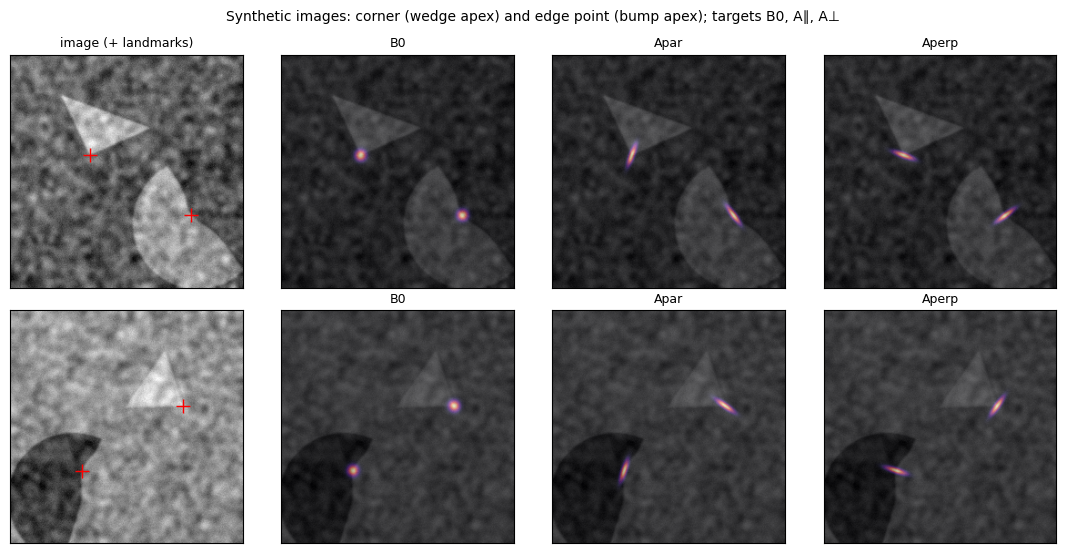

In [4]:
def _render(idx, stream):
    """One image (float32, z-scored), landmark positions (2, 2) [x, y] in px and reference-axis angles (2,) in degrees."""
    rng = np.random.default_rng([stream, idx])
    S = IMG
    yy, xx = np.mgrid[0:S, 0:S].astype(np.float32)
    tex = cv2.GaussianBlur(rng.standard_normal((S, S)).astype(np.float32), (0, 0), max(GEN["texture_sigma_frac"] * S, 0.5))
    img = GEN["texture_amp"] * tex / (tex.std() + 1e-8)
    g = rng.uniform(-0.2, 0.2, 2)
    img += g[0] * (xx / S - 0.5) + g[1] * (yy / S - 0.5)
    lo, hi = GEN["margin_frac"] * S, (1 - GEN["margin_frac"]) * S
    while True:
        p1, p2 = rng.uniform(lo, hi, 2), rng.uniform(lo, hi, 2)
        if np.hypot(*(p1 - p2)) >= GEN["min_landmark_distance_frac"] * S:
            break
    # corner: wedge with apex p1, bisector phi1, opening angle 2*half, arm length L (anti-aliased by signed distance)
    phi1, half = rng.uniform(-math.pi, math.pi), math.radians(rng.uniform(*GEN["wedge_angle_deg"])) / 2
    dx, dy = xx - p1[0], yy - p1[1]
    t = dx * math.cos(phi1) + dy * math.sin(phi1)
    n = -dx * math.sin(phi1) + dy * math.cos(phi1)
    sd_w = np.minimum(t * math.sin(half) - np.abs(n) * math.cos(half), GEN["wedge_len_frac"] * S - t)
    wedge = np.clip(0.5 + sd_w, 0, 1)
    # edge point: region below the curve n = h (exp(-t^2 / 2w^2) - 1) inside a disk around p2; the bump apex is p2
    phi2 = rng.uniform(-math.pi, math.pi)
    h, w = GEN["bump_height_frac"] * S, GEN["bump_width_frac"] * S
    dx, dy = xx - p2[0], yy - p2[1]
    t = dx * math.cos(phi2) + dy * math.sin(phi2)
    n = -dx * math.sin(phi2) + dy * math.cos(phi2)
    nb = h * (np.exp(-t ** 2 / (2 * w ** 2)) - 1)
    slope = -h * t / w ** 2 * np.exp(-t ** 2 / (2 * w ** 2))
    R = GEN["edge_disk_radius_frac"] * S
    off = rng.uniform(-1, 1) * GEN["edge_disk_offset_frac"] * R      # disk centre moved along the edge, so the arc does not mark p2
    sd_e = np.minimum((n - nb) / np.sqrt(1 + slope ** 2), R - np.hypot(t - off, n))
    edge = np.clip(0.5 + sd_e, 0, 1)
    c = rng.uniform(*GEN["contrast"], 2) * rng.choice([-1.0, 1.0], 2)
    img = img + c[0] * wedge + c[1] * edge
    img = cv2.GaussianBlur(img.astype(np.float32), (0, 0), max(GEN["blur_frac"] * S, 0.3))
    img = img + GEN["pixel_noise"] * rng.standard_normal((S, S)).astype(np.float32)
    img = (img - img.mean()) / (img.std() + 1e-8)
    pts = np.array([p1, p2], np.float32)
    ang = np.degrees([phi1, phi2]).astype(np.float32)
    return img, pts, ang

def make_set(n, stream):
    imgs, pts, angs = np.empty((n, IMG, IMG), np.float16), np.empty((n, K, 2), np.float32), np.empty((n, K), np.float32)
    for i in range(n):
        imgs[i], pts[i], angs[i] = _render(i, stream)
    return imgs, pts, angs

def arm_cov(arm, ang_deg):
    """(n, K, 2, 2) target covariances in px^2: round, or equal-area ratio-4 ovals along / across the reference axes."""
    n = ang_deg.shape[0]
    if arm == "B0":
        return np.tile(np.eye(2, dtype=np.float32) * SIGMA0_PX ** 2, (n, K, 1, 1))
    phi = np.radians(ang_deg + (0.0 if arm == "Apar" else 90.0))
    cs, sn = np.cos(phi), np.sin(phi)
    rot = np.stack([np.stack([cs, -sn], -1), np.stack([sn, cs], -1)], -2)
    d = np.zeros(phi.shape + (2, 2), np.float32)
    d[..., 0, 0], d[..., 1, 1] = SIGMA0_PX ** 2 * RATIO, SIGMA0_PX ** 2 / RATIO
    return (rot @ d @ np.swapaxes(rot, -1, -2)).astype(np.float32)

RUN_TABLE = pd.DataFrame([{"run_id": f"C0_SYNTH_{tier}_N{n}_{arm}_s{seed}", "tier": tier, "base": base, "n_train": n, "arm": arm, "seed": seed}
                          for tier, base in TIER_BASE.items() for n in N_TRAIN for seed in SEEDS for arm in ARMS])
assert RUN_TABLE.run_id.is_unique
todo = RUN_TABLE if RUN_IDS == "all" else RUN_TABLE[RUN_TABLE.run_id.isin(RUN_IDS)]
assert RUN_IDS == "all" or len(todo) == len(RUN_IDS), "unknown run ids in RUN_IDS"
N_MAX = int(todo.n_train.max()) if len(todo) else max(N_TRAIN)
t0 = time.time()
TRAIN = make_set(N_MAX, GEN["train_stream"])
TEST = make_set(N_TEST, GEN["test_stream"])
print(f"generated {N_MAX} training and {N_TEST} test images in {time.time() - t0:.1f} s | runs in this notebook: {len(todo)} of {len(RUN_TABLE)}")
RUN_TABLE.to_csv(Path(RUN_ROOT) / "run_table_synth.csv", index=False)

# visual check: two training images with their three targets
fig, axs = plt.subplots(2, 4, figsize=(11, 5.6))
for r in range(2):
    im, pt, an = TRAIN[0][r].astype(np.float32), TRAIN[1][r:r + 1], TRAIN[2][r:r + 1]
    axs[r, 0].imshow(im, cmap="gray"); axs[r, 0].plot(pt[0, :, 0], pt[0, :, 1], "r+", ms=10)
    for j, arm in enumerate(ARMS):
        tg = make_targets(torch.tensor(pt), torch.tensor(arm_cov(arm, an)), IMG, IMG)[0].numpy().max(0)
        axs[r, j + 1].imshow(im, cmap="gray"); axs[r, j + 1].imshow(tg, cmap="magma", alpha=0.6)
        axs[r, j + 1].set_title(arm, fontsize=9)
    for a in axs[r]:
        a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_title("image (+ landmarks)", fontsize=9)
fig.suptitle("Synthetic images: corner (wedge apex) and edge point (bump apex); targets B0, A∥, A⊥", fontsize=10)
fig.tight_layout()
fig.savefig(Path(RUN_ROOT) / "synth_examples.png", dpi=120)
RUN_TABLE.groupby(["tier", "n_train"]).size().unstack()

## 3. Training and evaluating one run

In [5]:
try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    _tqdm = None

def _grad_scaler():
    enabled = AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def lr_at(it):
    o = SYNTH_PROTOCOL["optimiser"]
    if it < o["warmup_iters"]:
        return o["lr"] * (it + 1) / o["warmup_iters"]
    prog = (it - o["warmup_iters"]) / max(1, ITERS - o["warmup_iters"])
    return 1e-6 + 0.5 * (o["lr"] - 1e-6) * (1 + math.cos(math.pi * prog))

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

TEST_X = torch.from_numpy(TEST[0])
CONV_N = min(50, N_MAX)
CONV_X = torch.from_numpy(TRAIN[0][:CONV_N])

@torch.no_grad()
def conv_mre(model):
    """MRE (px, quadratic decoder) on the first CONV_N training images: the convergence monitor."""
    model.eval()
    with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
        hm = model(CONV_X.to(DEVICE).float()[:, None])
    peaks, wins = heatmap_windows(hm.float())
    err = []
    for b in range(hm.shape[0]):
        for k in range(K):
            o = decode_window(wins[b, k])["quadratic"]
            err.append(math.hypot(peaks[b, k, 0] + o[0] - TRAIN[1][b, k, 0], peaks[b, k, 1] + o[1] - TRAIN[1][b, k, 1]))
    model.train()
    return float(np.mean(err))
DEC = SYNTH_PROTOCOL["decoders"]

@torch.no_grad()
def predict_test(model):
    model.eval()
    rows = []
    phi = np.radians(TEST[2])
    for s in range(0, N_TEST, 50):
        x = TEST_X[s:s + 50].to(DEVICE).float()[:, None]
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            hm = model(x)
        peaks, wins = heatmap_windows(hm.float())
        for b in range(hm.shape[0]):
            i = s + b
            for k in range(K):
                dec = decode_window(wins[b, k])
                gt = TEST[1][i, k]
                row = {"image": i, "landmark": k, "peak": float(hm[b, k].max())}
                for d in DEC:
                    ex, ey = peaks[b, k, 0] + dec[d][0] - gt[0], peaks[b, k, 1] + dec[d][1] - gt[1]
                    row[f"dx_{d}"], row[f"dy_{d}"] = float(ex), float(ey)
                row["fit_sxx"], row["fit_sxy"], row["fit_syy"] = dec["gauss_cov"]
                ex, ey = row[f"dx_{SYNTH_PROTOCOL['primary_decoder']}"], row[f"dy_{SYNTH_PROTOCOL['primary_decoder']}"]
                row["e_u"] = ex * math.cos(phi[i, k]) + ey * math.sin(phi[i, k])       # along the reference axis
                row["e_v"] = -ex * math.sin(phi[i, k]) + ey * math.cos(phi[i, k])      # across it
                rows.append(row)
    model.train()
    return pd.DataFrame(rows)

def train_run(run):
    out = Path(RUN_ROOT) / run["run_id"]
    if (out / "DONE").exists():
        return "done before"
    out.mkdir(parents=True, exist_ok=True)
    n, seed = int(run["n_train"]), int(run["seed"])
    torch.manual_seed(seed); np.random.seed(seed)
    model = UNet(in_ch=1, out_ch=K, base=int(run["base"])).to(DEVICE).to(memory_format=torch.channels_last)
    o = SYNTH_PROTOCOL["optimiser"]
    opt = torch.optim.AdamW(model.parameters(), lr=o["lr"], weight_decay=o["weight_decay"])
    scaler = _grad_scaler()
    X = torch.from_numpy(TRAIN[0][:n]).to(DEVICE)
    P = torch.from_numpy(TRAIN[1][:n]).to(DEVICE)
    C = torch.from_numpy(arm_cov(run["arm"], TRAIN[2][:n])).to(DEVICE)
    bar = _tqdm(total=ITERS, desc=run["run_id"], leave=True) if PROGRESS_BAR and _tqdm else None
    t_run, log = time.time(), []
    for it in range(ITERS):
        for gparam in opt.param_groups:
            gparam["lr"] = lr_at(it)
        idx = torch.from_numpy(np.random.default_rng([seed, n, it]).integers(0, n, BATCH_SIZE)).to(DEVICE)
        x, p, c = X[idx].float()[:, None].contiguous(memory_format=torch.channels_last), P[idx], C[idx]
        tgt = make_targets(p, c)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            pred = model(x)
        loss = mass_normalised_mse(pred, tgt, c)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        if (it + 1) % 100 == 0 or it == ITERS - 1:
            rec = {"iter": it + 1, "loss": float(loss), "lr": lr_at(it), "sec": time.time() - t_run}
            if (it + 1) % max(1, ITERS // 10) == 0 or it == ITERS - 1:
                rec["conv_mre_px"] = conv_mre(model)
            log.append(rec)
            if bar is not None:
                bar.update(it + 1 - bar.n); bar.set_postfix(loss=f"{float(loss):.4f}")
    if bar is not None:
        bar.close()
    pred = predict_test(model)
    pred.to_csv(out / "predictions_test.csv.gz", index=False)
    pd.DataFrame(log).to_csv(out / "train_log.csv", index=False)
    sha = "-"
    if SAVE_MODELS:
        tmp = out / "final.pt"
        torch.save(model.state_dict(), tmp)
        sha = file_sha256(tmp)
        tmp.rename(out / f"final_{sha[-8:]}.pt")
    cfg = {"run": {k: (v.item() if hasattr(v, "item") else v) for k, v in run.items()}, "protocol": SYNTH_PROTOCOL,
           "protocol_hash": SYNTH_HASH, "env": ENV_INFO, "model_sha256": sha, "train_seconds": time.time() - t_run}
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    (out / "DONE").write_text(f"{SYNTH_HASH}\n{sha}\n")
    return f"trained in {(time.time() - t_run) / 60:.1f} min"

## 4. Execute the selected runs

In [6]:
for _, run in todo.iterrows():
    print(run.run_id, "->", train_run(run.to_dict()))

C0_SYNTH_Extra-low_N100_Apar_s1:   0%|          | 0/30000 [00:00<?, ?it/s]

/tmp/ipykernel_2051/857605811.py:102: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  rec = {"iter": it + 1, "loss": float(loss), "lr": lr_at(it), "sec": time.time() - t_run}


C0_SYNTH_Extra-low_N100_Apar_s1 -> trained in 7.1 min


C0_SYNTH_Extra-low_N400_Apar_s1:   0%|          | 0/30000 [00:00<?, ?it/s]

C0_SYNTH_Extra-low_N400_Apar_s1 -> trained in 6.8 min


...

C0_SYNTH_High_N400_Apar_s1 -> trained in 27.3 min


C0_SYNTH_High_N1600_Apar_s1:   0%|          | 0/30000 [00:00<?, ?it/s]

C0_SYNTH_High_N1600_Apar_s1 -> trained in 27.3 min


C0_SYNTH_High_N6400_Apar_s1:   0%|          | 0/30000 [00:00<?, ?it/s]

C0_SYNTH_High_N6400_Apar_s1 -> trained in 26.9 min


## 9. Analysis (runs once all 72 runs are done; whichever notebook finishes last)

* Per run and landmark: primary-decoder errors projected on u (reference axis) and v; gross failures (|e| > 10 px) removed and
  reported as a rate; SD along u and v.
* Δ log SD = log SD(oval run) − log SD(paired B0 run), same tier, N, seed and axis. A∥: long axis on u (x = +log 2), short on v
  (x = −log 2); A⊥ the other way round. Usable if both cells have ≤ 5 % gross failures.
* Per tier × N × landmark: **α** = OLS slope with intercept over the usable observations (2 arms × 2 axes × 2 seeds);
  **a_wide** = mean Δ on the long axes / log 2; **a_narrow** = − mean Δ on the short axes / log 2 (> 0: narrowing reduces spread).
  Intervals: ± t × SE from the observations (only 2 seeds, so they are rough).
* Also: B0 accuracy, gross failures and baseline anisotropy SD_u / SD_v per tier and N (checks that the edge point is in fact
  poorly defined along the edge).

runs done: 72 of 72


conv_mre_final_px  conv_change_last_check
tier      n_train                                           
Extra-low 100                  0.291                   0.051
          400                  0.262                   0.044
          1600                 0.316                   0.028
          6400                 0.393                  -0.005
High      100                  0.117                  -0.000
          400                  0.108                  -0.133
          1600                 0.158                   0.006
          6400                 0.280                  -0.020
Low       100                  0.172                   0.013
          400                  0.162                  -0.082
          1600                 0.216                  -0.014
          6400                 0.301                  -0.046

arm                 Apar  Aperp     B0
tier      n_train                     
Extra-low 100      0.596  0.644  0.734
          400      0.105  0.199  0.160
          1600     0.023  0.026  0.025
          6400     0.010  0.011  0.007
High      100      0.160  0.330  0.167
          400      0.029  0.035  0.029
          1600     0.016  0.017  0.018
          6400     0.007  0.005  0.006
Low       100      0.363  0.476  0.516
          400      0.053  0.068  0.044
          1600     0.016  0.017  0.021
          6400     0.007  0.008  0.007

mre_px   fail   sd_u   sd_v  anisotropy_u_over_v
tier      n_train landmark                                                    
Extra-low 100     corner      73.304  0.807  2.421  3.897                0.621
                  edge point  50.231  0.662  5.156  1.913                2.696
          400     corner      18.868  0.204  1.362  2.151                0.633
                  edge point   9.849  0.115  3.852  1.043                3.692
          1600    corner       3.816  0.043  0.661  0.805                0.821
                  edge point   1.468  0.008  1.005  0.321                3.132
          6400    corner       1.407  0.013  0.541  0.612                0.885
                  edge point   0.700  0.002  0.741  0.257                2.880
High      100     corner      11.976  0.154  0.785  1.031                0.761
                  edge point   9.796  0.180  4.704  0.788                5.969
          400     corner       4.103  0.048  0.745  0.639                1.165
                  edge point   1.933  0.010  1.527  0.315                4.844
          1600    corner       2.952  0.034  0.516  0.464                1.112
                  edge point   0.679  0.003  0.746  0.183                4.068
          6400    corner       1.021  0.011  0.410  0.417                0.984
                  edge point   0.511  0.002  0.561  0.156                3.603
Low       100     corner      53.187  0.612  1.885  3.131                0.602
                  edge point  24.570  0.420  4.839  1.541                3.140
          400     corner       6.064  0.075  0.746  0.881                0.847
                  edge point   2.494  0.013  2.348  0.491                4.779
          1600    corner       3.012  0.037  0.598  0.646                0.925
                  edge point   0.862  0.006  0.855  0.232                3.686
          6400    corner       1.312  0.013  0.356  0.457                0.779
                  edge point   0.575  0.002  0.579  0.196                2.951

a_narrow               a_wide                alpha  \
n_train                  400    1600   6400   400    1600   6400   400    
landmark   tier                                                           
corner     Extra-low      NaN  0.260  0.371    NaN  0.677  0.622    NaN   
           High         0.650  0.364  0.382  0.359  0.704  0.611  0.505   
           Low            NaN  0.415  0.268    NaN  0.752  0.925    NaN   
edge point Extra-low      NaN  0.258  0.280    NaN  0.608  0.759    NaN   
           High         0.119  0.174  0.225  1.119  0.721  0.839  0.619   
           Low          0.410  0.115  0.071  0.559  0.897  0.942  0.485   

                                    
n_train                1600   6400  
landmark   tier                     
corner     Extra-low  0.468  0.497  
           High       0.534  0.497  
           Low        0.583  0.597  
edge point Extra-low  0.433  0.520  
           High       0.448  0.532  
           Low        0.506  0.507

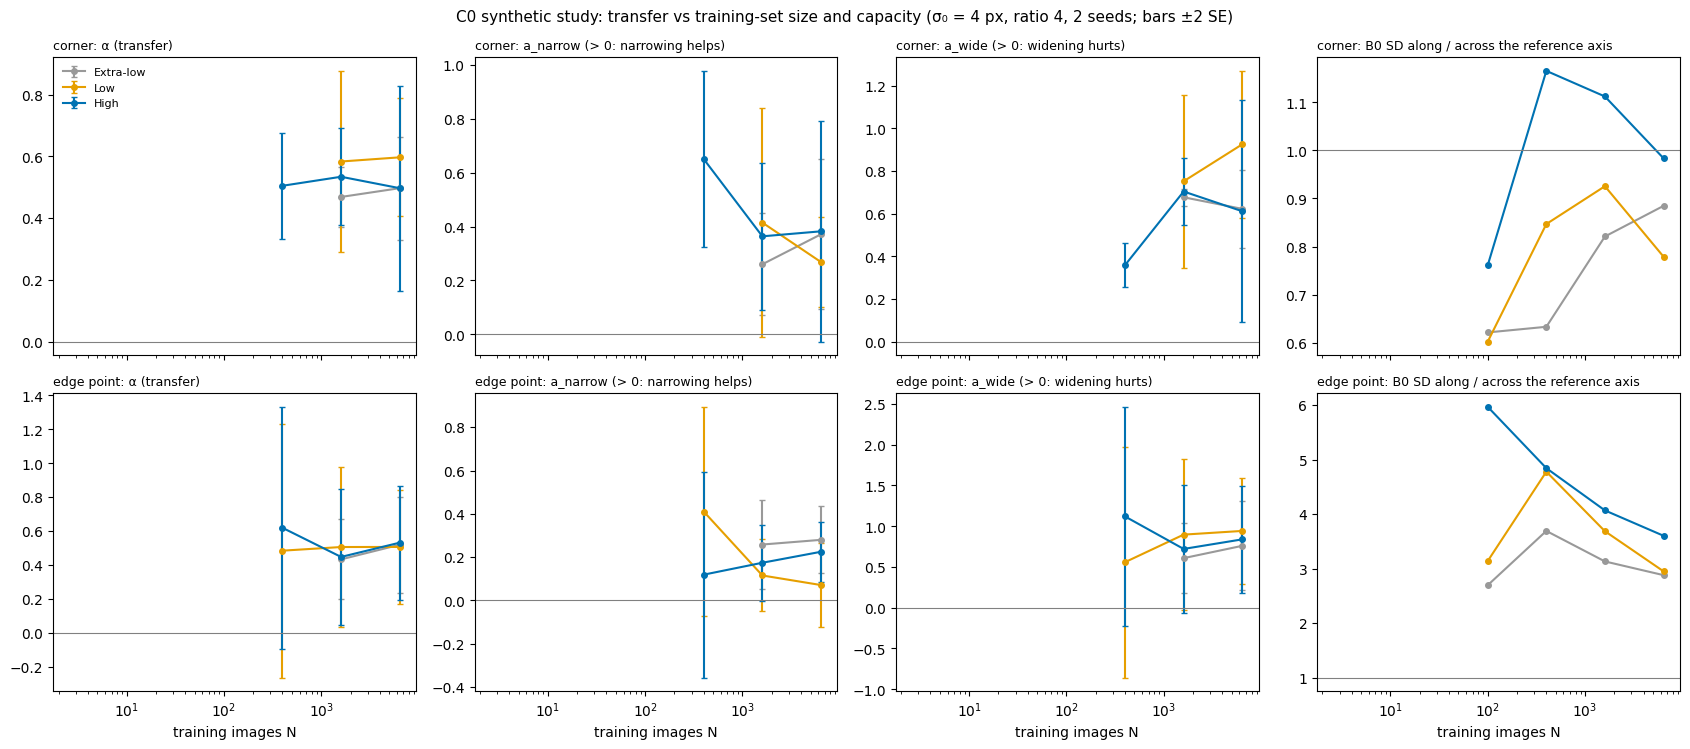

In [7]:
AGG = Path(RUN_ROOT) / "synth_summary"
AGG.mkdir(exist_ok=True)
_LOCK = AGG / ".analysis.lock"
n_done = sum((Path(RUN_ROOT) / r / "DONE").exists() for r in RUN_TABLE.run_id)
print(f"runs done: {n_done} of {len(RUN_TABLE)}")

def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print("another notebook is running the analysis now; skipped here")
        return False

HAVE_LOCK = n_done == len(RUN_TABLE) and _acquire_lock()
if HAVE_LOCK:
    try:
        H = math.log(2)
        cells = []
        for _, run in RUN_TABLE.iterrows():
            d = Path(RUN_ROOT) / run.run_id
            assert (d / "DONE").read_text().split()[0] == SYNTH_HASH, f"{run.run_id}: protocol differs"
            p = pd.read_csv(d / "predictions_test.csv.gz")
            p["r"] = np.hypot(p.e_u, p.e_v)
            for k, g in p.groupby("landmark"):
                ok = g[g.r <= GROSS_PX]
                cells.append({**run.to_dict(), "landmark": LM_NAMES[k], "fail_rate": 1 - len(ok) / len(g),
                              "mre_px": g.r.mean(), "sd_u": ok.e_u.std(ddof=1), "sd_v": ok.e_v.std(ddof=1)})
        CELLS = pd.DataFrame(cells)
        CELLS.round(5).to_csv(AGG / "synth_cells.csv", index=False)
        b0 = CELLS[CELLS.arm == "B0"].set_index(["tier", "n_train", "seed", "landmark"])
        obs = []
        for _, c in CELLS[CELLS.arm != "B0"].iterrows():
            b = b0.loc[(c.tier, c.n_train, c.seed, c.landmark)]
            usable = c.fail_rate <= 0.05 and b.fail_rate <= 0.05
            long_ax, short_ax = ("u", "v") if c.arm == "Apar" else ("v", "u")
            for axis, ax_name, x in (("long", long_ax, H), ("short", short_ax, -H)):
                obs.append({"tier": c.tier, "n_train": c.n_train, "seed": c.seed, "landmark": c.landmark, "arm": c.arm,
                            "axis": axis, "direction": ax_name, "x": x, "usable": usable,
                            "dlog_sd": math.log(c[f"sd_{ax_name}"] / b[f"sd_{ax_name}"])})
        OBS = pd.DataFrame(obs)
        OBS.round(5).to_csv(AGG / "synth_axis_observations.csv", index=False)
        rows = []
        for (tier, n, lm), g in OBS[OBS.usable].groupby(["tier", "n_train", "landmark"]):
            row = {"tier": tier, "n_train": n, "landmark": lm, "n_obs": len(g)}
            if len(g) >= 4 and g.x.nunique() == 2:
                X = np.column_stack([np.ones(len(g)), g.x])
                bcoef, *_ = np.linalg.lstsq(X, g.dlog_sd.values, rcond=None)
                r = g.dlog_sd.values - X @ bcoef
                se = math.sqrt((r @ r / max(len(g) - 2, 1)) * np.linalg.inv(X.T @ X)[1, 1])
                lg, sh = g[g.axis == "long"].dlog_sd, g[g.axis == "short"].dlog_sd
                row.update({"alpha": bcoef[1], "alpha_se": se, "a_wide": lg.mean() / H,
                            "a_wide_se": lg.std(ddof=1) / math.sqrt(len(lg)) / H if len(lg) > 1 else np.nan,
                            "a_narrow": -sh.mean() / H, "a_narrow_se": sh.std(ddof=1) / math.sqrt(len(sh)) / H if len(sh) > 1 else np.nan})
            rows.append(row)
        RES = pd.DataFrame(rows)
        RES.round(5).to_csv(AGG / "synth_alpha_by_tier_N.csv", index=False)
        B0T = CELLS[CELLS.arm == "B0"].groupby(["tier", "n_train", "landmark"]).agg(mre_px=("mre_px", "mean"), fail=("fail_rate", "mean"),
                                                                                    sd_u=("sd_u", "mean"), sd_v=("sd_v", "mean"))
        B0T["anisotropy_u_over_v"] = B0T.sd_u / B0T.sd_v
        B0T.round(4).to_csv(AGG / "synth_baseline.csv")
        conv = []
        for _, run in RUN_TABLE.iterrows():
            tl = pd.read_csv(Path(RUN_ROOT) / run.run_id / "train_log.csv").dropna(subset=["conv_mre_px"])
            v = tl.conv_mre_px.values
            conv.append({"run_id": run.run_id, "tier": run.tier, "n_train": run.n_train, "arm": run.arm, "conv_mre_final_px": v[-1],
                         "conv_change_last_check": v[-1] / v[-2] - 1 if len(v) > 1 else np.nan})
        CONV = pd.DataFrame(conv)
        CONV.round(4).to_csv(AGG / "synth_convergence.csv", index=False)
        display(CONV.groupby(["tier", "n_train"])[["conv_mre_final_px", "conv_change_last_check"]].mean().round(3))
        FAILS = CELLS.pivot_table(index=["tier", "n_train"], columns="arm", values="fail_rate", aggfunc="mean")
        FAILS.round(4).to_csv(AGG / "synth_fail_rates.csv")

        tiers = list(TIER_BASE)
        col = dict(zip(tiers, ["#999999", "#E69F00", "#0072B2"][-len(tiers):]))
        fig, axs = plt.subplots(2, 4, figsize=(17, 7.6), sharex=True)
        for r, lm in enumerate(LM_NAMES):
            for j, (q, lab) in enumerate((("alpha", "α (transfer)"), ("a_narrow", "a_narrow (> 0: narrowing helps)"),
                                          ("a_wide", "a_wide (> 0: widening hurts)"))):
                ax = axs[r, j]
                for tier in tiers:
                    g = RES[(RES.tier == tier) & (RES.landmark == lm)].sort_values("n_train")
                    if q in g:
                        ax.errorbar(g.n_train, g[q], yerr=2 * g[f"{q}_se"], marker="o", ms=4, capsize=2, color=col[tier], label=tier)
                ax.axhline(0, color="0.5", lw=0.8)
                ax.set_xscale("log"); ax.set_title(f"{lm}: {lab}", fontsize=9, loc="left")
                if r == 1:
                    ax.set_xlabel("training images N")
            ax = axs[r, 3]
            for tier in tiers:
                g = B0T.xs(lm, level="landmark").loc[tier]
                ax.plot(g.index, g.anisotropy_u_over_v, marker="o", ms=4, color=col[tier], label=tier)
            ax.axhline(1, color="0.5", lw=0.8); ax.set_xscale("log")
            ax.set_title(f"{lm}: B0 SD along / across the reference axis", fontsize=9, loc="left")
            if r == 1:
                ax.set_xlabel("training images N")
        axs[0, 0].legend(fontsize=8, frameon=False)
        fig.suptitle(f"C0 synthetic study: transfer vs training-set size and capacity (σ₀ = {SIGMA0_PX:g} px, ratio {RATIO:g}, "
                     f"{len(SEEDS)} seeds; bars ±2 SE)", fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "synth_transfer_vs_N.png", dpi=150)
        summary = {"protocol_hash": SYNTH_HASH, "runs": len(RUN_TABLE),
                   "max_fail_rate_B0": float(CELLS[CELLS.arm == "B0"].fail_rate.max()),
                   "alpha_by_tier_N": RES.round(4).to_dict("records")}
        (AGG / "synth_summary.json").write_text(json.dumps(summary, indent=1, default=float))
        display(FAILS.round(3))
        display(B0T.round(3))
        display(RES.pivot_table(index=["landmark", "tier"], columns="n_train", values=["alpha", "a_narrow", "a_wide"]).round(3))
    finally:
        _LOCK.unlink(missing_ok=True)